# What limits HOM visibility? Polarization vs. spectral mismatch

A Hong–Ou–Mandel (HOM) dip with only ~64% visibility leaves you asking *which* imperfection ate the
missing contrast. This notebook covers two common causes for **signal–idler HOM interference from a
type-II ppKTP source** (e.g. one arm of a Sagnac entangled-photon source, with the idler polarization
rotated by 90° before the beam splitter):

1. **Polarization mismatch.** After the 90° rotation the two photons don't have exactly the same polarization.
2. **Spectral mismatch.** The signal and idler spectra don't overlap, e.g. because the crystal temperature
   is off the degenerate point.

It covers:

- **Part 1:** the math, including the polarization overlap $|\langle p_1|p_2\rangle|^2$.
- **Part 2:** polarization only, with linear offsets and elliptical states.
- **Part 3:** spectral mismatch. This section also shows that, for photons from the **same pair**, the
  density-matrix formula is *not* the right model. It is replaced by the JSA exchange overlap.
- **Part 4:** both effects combined, plus a fit template you can point at experimental data.
- **Part 5:** the same question for photons from **two independent crystals**: here the density-matrix
  model is exact and the visibility ceiling is the spectral purity.

The two experiments need two different models, so `HOMAnalyzer` makes you pick one explicitly:

| experiment | call | spectral term $X(\tau)$ |
|---|---|---|
| signal and idler of one pair (Parts 2–4) | `HOMAnalyzer.same_pair(results, pol_signal=, pol_idler=)` | JSA exchange overlap |
| photons from two independent sources (Part 5) | `HOMAnalyzer.independent(res_a, res_b, mode_a, mode_b, pol_a=, pol_b=)` | $\mathrm{Re}\,\mathrm{Tr}[\rho_a\rho_b(\tau)]$ |

Both return a `HOMResults` that keeps the factors of the visibility separate: `beam_splitter_factor`,
`polarization_overlap` and `spectral_overlap` (the full $X(\tau)$), with `visibility` and
`visibility_breakdown()` on top.

## Part 1: The math

### Two independent photons

Photon 1 enters beam-splitter port $a$ in the (mixed) spectral state $\rho_1$ and polarization $|p_1\rangle$.
Photon 2 enters port $b$ in $\rho_2$, $|p_2\rangle$. If the two photons are **uncorrelated**, the input
state is a product,

$$
\varrho_\text{in} = \big(\rho_1 \otimes |p_1\rangle\langle p_1|\big)_a \otimes \big(\rho_2 \otimes |p_2\rangle\langle p_2|\big)_b .
$$

A lossless beam splitter with reflectivity $R$ and transmissivity $T = 1 - R$ maps
$a^\dagger \to \sqrt{T}\,c^\dagger + \sqrt{R}\,d^\dagger$ and $b^\dagger \to \sqrt{R}\,c^\dagger - \sqrt{T}\,d^\dagger$.
There are two ways to get one photon in each output: both transmitted (amplitude $\propto T$) or both
reflected (amplitude $\propto -R$). For pure states, the probability of a coincidence is

$$
P_c = T^2 + R^2 - 2RT\,\big|\langle \psi_1 | \psi_2 \rangle\big|^2 .
$$

The two paths interfere only as far as the photons are **indistinguishable in every degree of
freedom**. For mixed states, $|\langle\psi_1|\psi_2\rangle|^2 \to \mathrm{Tr}[\varrho_1\varrho_2]$. The
spectral and polarization parts are a tensor product, so the trace factorizes:

$$
\boxed{\;P_c(\tau) = R^2 + T^2 - 2RT\;\underbrace{|\langle p_1|p_2\rangle|^2}_{\text{polarization}}\;
\underbrace{\mathrm{Re}\,\mathrm{Tr}\!\big[\rho_1\,\rho_2(\tau)\big]}_{\text{spectral}}\;}
$$

This is the formula behind `HOMAnalyzer.independent`. The `pol_a`/`pol_b` arguments supply the
polarization factor, which defaults to 1 (identical polarizations).

### Delay

Delaying photon 2 by $\tau$ multiplies each frequency component by a phase. In the frequency-bin basis
the density matrix becomes

$$
\rho_2(f, f'; \tau) = e^{-i 2\pi (f - f')\tau}\,\rho_2(f, f') ,
$$

which is `hom_math.apply_delay_to_rho_freq`. At large $|\tau|$ the phases average out,
$\mathrm{Tr}[\rho_1\rho_2(\tau)] \to 0$, and $P_c \to R^2 + T^2$, the classical baseline.

### Why a "relative phase" alone does nothing

A frequency-independent phase on photon 2, $|\psi_2\rangle \to e^{i\varphi}|\psi_2\rangle$, gives
$\rho_2 \to e^{i\varphi}\rho_2 e^{-i\varphi} = \rho_2$. The dip doesn't change. A phase only matters if it
(a) depends on frequency (dispersion, as in the delay operator above), or (b) sits *between the H and V
components* of the polarization. Case (b) makes the polarization elliptical, and its whole effect enters
through $|\langle p_1|p_2\rangle|^2$.

### Polarization overlap

For Jones vectors $p = (p_H, p_V)$,

$$
|\langle p_1|p_2\rangle|^2 = \frac{|p_{1H}^* p_{2H} + p_{1V}^* p_{2V}|^2}{\|p_1\|^2\|p_2\|^2}.
$$

- Linear polarizations at relative angle $\theta$: $|\langle p_1|p_2\rangle|^2 = \cos^2\theta$.
- Diagonal $|D\rangle = (1,1)/\sqrt{2}$ against $(1, e^{i\phi})/\sqrt{2}$ (a birefringent phase $\phi$
  in one arm, e.g. from a fiber): $|\langle p_1|p_2\rangle|^2 = (1+\cos\phi)/2$.

### Visibility

With $V \equiv (P_c^\text{max} - P_c^\text{min})/P_c^\text{max}$ and the dip at $\tau = 0$:

$$
V = \frac{2RT}{R^2+T^2}\;|\langle p_1|p_2\rangle|^2\;\mathrm{Tr}[\rho_1\rho_2].
$$

The three factors (beam-splitter balance, polarization, spectrum) multiply. `HOMResults.visibility_breakdown()`
returns exactly these three factors and their product. Only the spectral factor can change the dip *shape*.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import curve_fit

from photonpairlab import (
    Crystal,
    HOMAnalyzer,
    MaterialFactory,
    PulsedLaser,
    SPDC_Plotter,
    SPDC_Simulation,
    SPDCGridConfig,
    SpectralAnalyzer,
)
from photonpairlab.spdc.analysis import linear_polarization, polarization_overlap

warnings.filterwarnings("ignore")
SPDC_Plotter.use_style()  # every figure below uses the SPDC_Plotter chart style

## Setup

KTP, type-II, 30 mm, periodic poling designed for degenerate 1550 nm at 25 °C, pumped by a 1.7 ps
pulsed laser at 775 nm. The same source as in `demo.ipynb`.

Both HOM models require the interfering photons on the **same wavelength grid**. To interfere signal with
idler, we therefore use identical explicit ranges, `signal_range == idler_range`.

In [2]:
material = MaterialFactory.create("ktp1")
laser = PulsedLaser(775e-9, pulse_duration=1.7e-12)
crystal_length = 30e-3
wl0 = 1550e-9
T_design = 25.0

wl_range = (1544e-9, 1556e-9)
grid = SPDCGridConfig(steps=100, signal_range=wl_range, idler_range=wl_range)

H = linear_polarization(0.0)


def simulate(T=T_design, mode="periodic", w=None):
    # Pole for degeneracy at T_design, then operate the crystal at temperature T.
    # mode/w select the poling ("periodic" or apodized "subcoh" with domain width w).
    extra = {} if w is None else {"w": w}
    design = Crystal(crystal_length=crystal_length, material=material, pm_strategy="quasi",
                     spdc_type="type-II", T=T_design, **extra)
    poling = design.generate_poling(laser=laser, mode=mode,
                                    wavelength_signal=wl0, wavelength_idler=wl0, resolution=5)
    crystal = Crystal(crystal_length=crystal_length, material=material, pm_strategy="quasi",
                      spdc_type="type-II", T=T, coherence_length=design.coherence_length, **extra)
    crystal.apply_poling(poling)
    sim = SPDC_Simulation(crystal, laser, wavelength_signal=wl0, wavelength_idler=wl0, grid=grid)
    return sim.run()


results = simulate()
taus = np.linspace(-6e-12, 6e-12, 601)
taus_ps = taus * 1e12

## Part 2: Polarization only

We interfere the signal with the idler of the *same* pair (spectrally degenerate) using
`HOMAnalyzer.same_pair`, and rotate the idler by $\theta$ away from the signal. The polarization factor
multiplies the whole dip, so the **shape is unchanged and only the depth scales**, as $\cos^2\theta$.
(Part 3 explains why `same_pair`, and not the density-matrix model, is the right one here. The
$\cos^2\theta$ scaling is the same in both.)

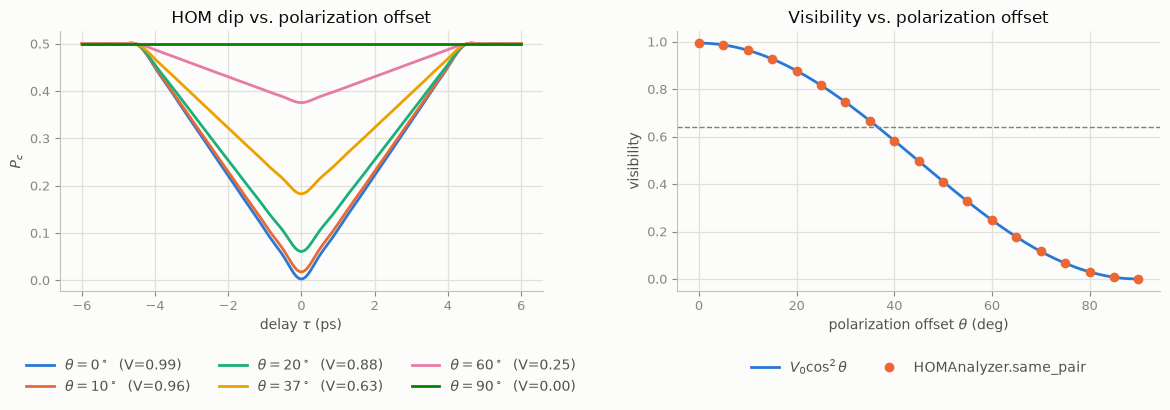

V0 (identical polarizations) = 0.994
Polarization offset alone needed for 64% of V0: theta = 36.9 deg


In [3]:
fig, (ax_dip, ax_v) = plt.subplots(1, 2, figsize=(12, 4.2))
for deg in [0, 10, 20, 37, 60, 90]:
    res = HOMAnalyzer.same_pair(results, taus_s=taus,
                                pol_signal=H, pol_idler=linear_polarization(np.deg2rad(deg)))
    ax_dip.plot(taus_ps, res.coincidence_probabilities,
                label=fr"$\theta={deg}^\circ$  (V={res.visibility:.2f})")
ax_dip.set(xlabel=r"delay $\tau$ (ps)", ylabel=r"$P_c$", title="HOM dip vs. polarization offset")
SPDC_Plotter.style_legend(ax_dip, ncol=3)

V0 = HOMAnalyzer.same_pair(results, taus_s=taus).visibility
thetas = np.linspace(0, 90, 19)
V_num = [HOMAnalyzer.same_pair(results, taus_s=np.array([0.0]),
                               pol_signal=H, pol_idler=linear_polarization(np.deg2rad(t))).visibility
         for t in thetas]
th_fine = np.linspace(0, 90, 300)
ax_v.plot(th_fine, V0 * np.cos(np.deg2rad(th_fine))**2, label=r"$V_0\cos^2\theta$")
ax_v.plot(thetas, V_num, "o", label="HOMAnalyzer.same_pair")
ax_v.axhline(0.64, color="gray", ls="--", lw=1)
ax_v.set(xlabel=r"polarization offset $\theta$ (deg)", ylabel="visibility",
         title="Visibility vs. polarization offset")
SPDC_Plotter.style_legend(ax_v, ncol=2)
plt.tight_layout()
plt.show()

print(f"V0 (identical polarizations) = {V0:.3f}")
print(f"Polarization offset alone needed for 64% of V0: theta = {np.rad2deg(np.arccos(np.sqrt(0.64))):.1f} deg")

$\theta \approx 37^\circ$ is a large error for a half-wave plate. A misaligned plate alone is therefore
unlikely to explain 64%. A **birefringent phase** in a fiber (an elliptical state) is a more plausible
source of polarization distinguishability. With diagonal input, a phase $\phi$ between H and V gives
$(1+\cos\phi)/2$:

In [4]:
D = np.array([1, 1]) / np.sqrt(2)
for phi_deg in [0, 30, 60, 74, 90, 180]:
    p2 = np.array([1, np.exp(1j * np.deg2rad(phi_deg))]) / np.sqrt(2)
    print(f"phi = {phi_deg:3d} deg  ->  |<p1|p2>|^2 = {polarization_overlap(D, p2):.3f}"
          f"   (analytic {(1 + np.cos(np.deg2rad(phi_deg))) / 2:.3f})")

phi =   0 deg  ->  |<p1|p2>|^2 = 1.000   (analytic 1.000)
phi =  30 deg  ->  |<p1|p2>|^2 = 0.933   (analytic 0.933)
phi =  60 deg  ->  |<p1|p2>|^2 = 0.750   (analytic 0.750)
phi =  74 deg  ->  |<p1|p2>|^2 = 0.638   (analytic 0.638)
phi =  90 deg  ->  |<p1|p2>|^2 = 0.500   (analytic 0.500)
phi = 180 deg  ->  |<p1|p2>|^2 = 0.000   (analytic 0.000)


## Part 3: Spectral mismatch

### The density-matrix formula underestimates same-pair interference

The $\rho_1\rho_2$ formula assumes **uncorrelated** photons. Signal and idler from one SPDC event are
spectrally *correlated*. Their joint state is

$$
|\psi\rangle = \iint d\omega_s\, d\omega_i\; f(\omega_s,\omega_i)\, a^\dagger(\omega_s)\, b^\dagger(\omega_i)\, |0\rangle ,
$$

and the same beam-splitter calculation (now keeping the full JSA $f$) gives

$$
P_c(\tau) = R^2 + T^2 - 2RT\,|\langle p_1|p_2\rangle|^2\;
\mathrm{Re}\!\iint d\omega_s\, d\omega_i\; f^*(\omega_s,\omega_i)\, f(\omega_i,\omega_s)\, e^{-i(\omega_s-\omega_i)\tau}
\qquad(\|f\| = 1).
$$

The interference term is the overlap of the JSA with its **signal↔idler-exchanged** copy, not the
overlap of the two marginals. The two agree only when the JSA factorizes,
$f = \phi_s(\omega_s)\phi_i(\omega_i)$. In that case the exchange integral equals
$|\langle\phi_s|\phi_i\rangle|^2 = \mathrm{Tr}[\rho_s\rho_i]$. A correlated (impure) but exchange-symmetric
JSA gives **perfect** same-pair interference, while the $\rho$ formula would cap it near the purity.

On our grid the JSA has idler along axis 0 and signal along axis 1. With identical axes, the exchange is
just a transpose. This is `hom_math.exchange_overlap_vs_delay`, used by `HOMAnalyzer.same_pair`.

Below, the same simulation goes through both models. Calling `independent` with the signal and idler of
one results object is exactly the mistake the library warns about (warnings are silenced in this
notebook); here we do it on purpose to compare.

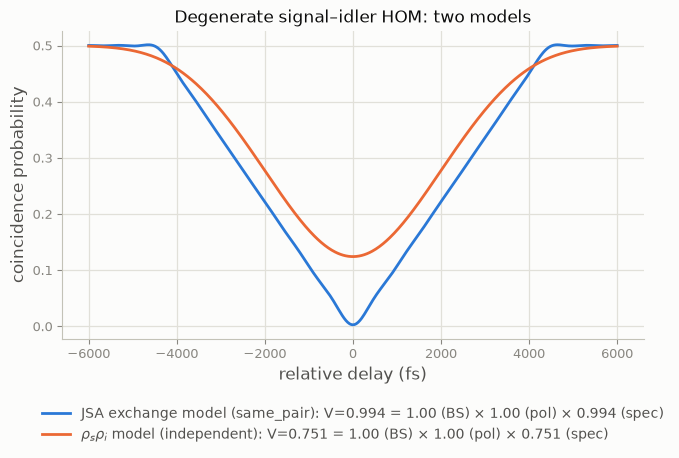

spectral purity = 0.756
X(0): exchange = 0.994,  Tr[rho_s rho_i] = 0.751


In [5]:
same_pair = HOMAnalyzer.same_pair(results, taus_s=taus)
rho_model = HOMAnalyzer.independent(results, results, "signal", "idler", taus_s=taus)  # wrong model, on purpose

fig, ax = plt.subplots(figsize=(7.5, 4))
SPDC_Plotter.plot_hom_dip(
    {"JSA exchange model (same_pair)": same_pair, r"$\rho_s\rho_i$ model (independent)": rho_model},
    fig=fig, ax=ax, show_visibility=True,
)
ax.set_title("Degenerate signal–idler HOM: two models")
plt.show()

print(f"spectral purity = {same_pair.purity1:.3f}")
print(f"X(0): exchange = {same_pair.overlap_at_zero_delay:.3f},  Tr[rho_s rho_i] = {rho_model.overlap_at_zero_delay:.3f}")

At perfect degeneracy the exchange model gives a near-unit dip, as expected for a type-II source with a
symmetric-enough JSA. The $\rho$ model is capped by the purity. **For the signal–idler experiment, use
`HOMAnalyzer.same_pair`.** Use `HOMAnalyzer.independent` for photons from *independent* sources (e.g. two
heralded photons, Part 5). The polarization factor enters both models identically.

### Detuning by temperature

Running the crystal away from the design temperature shifts phase matching to a non-degenerate pair:
$\lambda_s \ne \lambda_i$. Below we report the detuning as the difference of the marginal-spectrum
centroids, $\Delta\lambda = \bar\lambda_s - \bar\lambda_i$, which is what a spectrometer measures
(`SpectralAnalyzer.marginal_centroids_nm`).

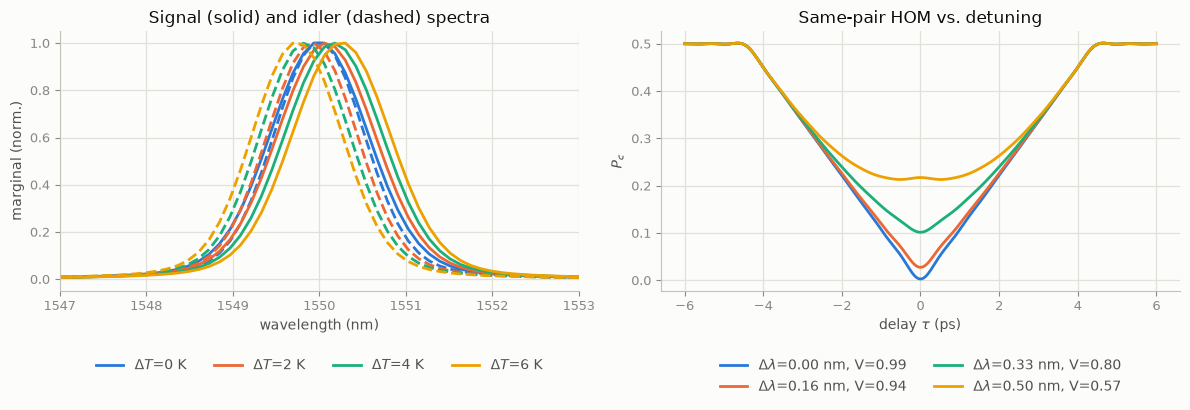

In [6]:
def centroid_detuning_nm(res):
    signal_nm, idler_nm = SpectralAnalyzer(res).marginal_centroids_nm()
    return signal_nm - idler_nm


fig, (ax_spec, ax_dip) = plt.subplots(1, 2, figsize=(12, 4.2))
for dT in [0, 2, 4, 6]:
    res = simulate(T_design + dT)
    jsi = np.abs(res.JSA) ** 2
    wl_nm = np.asarray(res.SignalWavelengths) * 1e9
    line, = ax_spec.plot(wl_nm, jsi.sum(axis=0) / jsi.sum(axis=0).max(), label=fr"$\Delta T$={dT} K")
    ax_spec.plot(wl_nm, jsi.sum(axis=1) / jsi.sum(axis=1).max(), ls="--", color=line.get_color())
    hom_dT = HOMAnalyzer.same_pair(res, taus_s=taus)
    ax_dip.plot(taus_ps, hom_dT.coincidence_probabilities, color=line.get_color(),
                label=fr"$\Delta\lambda$={centroid_detuning_nm(res):.2f} nm, V={hom_dT.visibility:.2f}")
ax_spec.set(xlim=(1547, 1553), xlabel="wavelength (nm)", ylabel="marginal (norm.)",
            title="Signal (solid) and idler (dashed) spectra")
SPDC_Plotter.style_legend(ax_spec, ncol=4)
ax_dip.set(xlabel=r"delay $\tau$ (ps)", ylabel=r"$P_c$", title="Same-pair HOM vs. detuning")
SPDC_Plotter.style_legend(ax_dip, ncol=2)
plt.tight_layout()
plt.show()

Unlike a polarization offset, detuning **also changes the dip shape**. The triangular wings, whose
$\approx\pm 4.7$ ps width is set by the group-velocity mismatch over the 30 mm crystal, stay where they
are. Only the bottom of the dip fills in: the interference term picks up a beat $\propto\cos(\Delta\omega\,\tau)$
that matters near $\tau = 0$, so the dip flattens and, at larger detuning, turns into a W shape. A
polarization offset instead scales the *whole* dip, wings included. This shape difference is what lets
a fit tell the two effects apart.

## Part 4: Both effects together

The polarization and spectral factors multiply: $V = |\langle p_1|p_2\rangle|^2 \cdot V_\text{spec}(\Delta\lambda)$.
We tabulate the exchange-model dip on a grid of temperature offsets once and interpolate it in
$\Delta T$. The table is reused by the fit below.

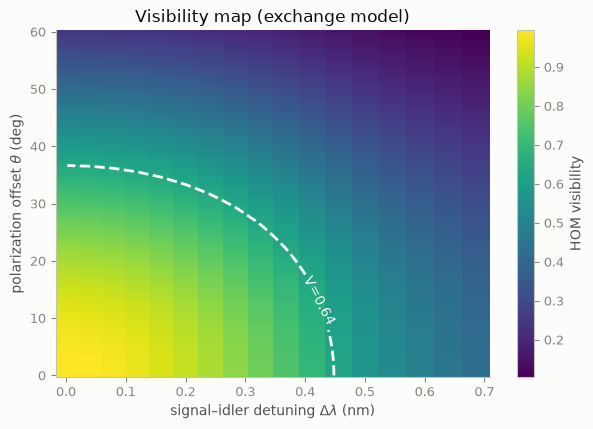

In [7]:
dTs = np.arange(0.0, 8.01, 0.5)
dip_taus_ps = np.linspace(-6, 6, 241)
X_table, detunings = [], []
for dT in dTs:
    res = simulate(T_design + dT)
    X_table.append(HOMAnalyzer.same_pair(res, taus_s=dip_taus_ps * 1e-12).spectral_overlap)  # X(tau)
    detunings.append(centroid_detuning_nm(res))
X_table, detunings = np.array(X_table), np.array(detunings)
X_interp = RegularGridInterpolator((dTs, dip_taus_ps), X_table, bounds_error=False, fill_value=0.0)

V_spec = X_table.max(axis=1)
th_grid = np.linspace(0, 60, 121)
V_map = np.cos(np.deg2rad(th_grid))[:, None] ** 2 * V_spec[None, :]

fig, ax = plt.subplots(figsize=(7, 4.5))
pcm = ax.pcolormesh(detunings, th_grid, V_map, shading="auto", cmap="viridis")
cs = ax.contour(detunings, th_grid, V_map, levels=[0.64], colors="w", linestyles="--")
ax.clabel(cs, fmt="V=0.64")
fig.colorbar(pcm, label="HOM visibility")
ax.set(xlabel=r"signal–idler detuning $\Delta\lambda$ (nm)", ylabel=r"polarization offset $\theta$ (deg)",
       title="Visibility map (exchange model)")
plt.show()

The dashed line marks every combination that gives 64%. Visibility alone can't tell which effect
dominates; the dip **shape** is needed.

### Fit template

Model the measured coincidences as

$$
N_c(\tau) = N_0\Big[\tfrac12 - \tfrac12\cos^2\theta\; X(\tau - \tau_0;\,\Delta T)\Big],
$$

with free parameters polarization offset $\theta$, detuning $\Delta T$ (equivalently
$\Delta\lambda$), delay offset $\tau_0$ and normalization $N_0$. Below we fit synthetic Poisson data
generated with a known ground truth. To use real data, replace `tau_data_ps`/`counts` with measurement data. If the source isn't this exact crystal, re-run `simulate` with the matching
parameters first.

theta =  20.5 +- 1.5 deg   (true 20.0)
dT    =  4.51 +- 0.17 K     (true 4.50)  ->  dlambda = 0.37 nm
tau0  =  0.13 +- 0.02 ps
corr(theta, dT) = -0.92


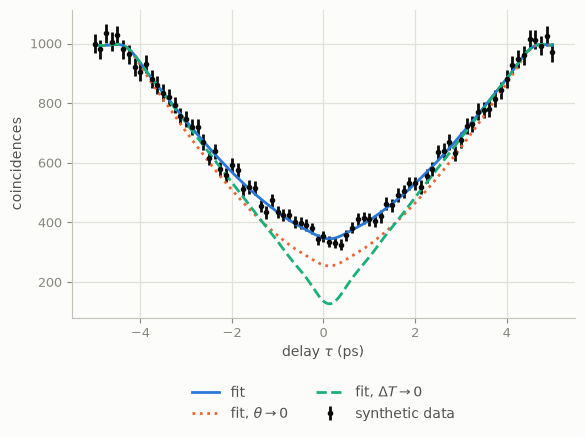

In [8]:
def dip_model(tau_ps, theta, dT, tau0_ps, N0):
    pts = np.column_stack([np.full_like(tau_ps, dT), tau_ps - tau0_ps])
    return N0 * (0.5 - 0.5 * np.cos(theta) ** 2 * X_interp(pts))


rng = np.random.default_rng(1)
tau_data_ps = np.linspace(-5, 5, 81)
truth = {"theta": np.deg2rad(20), "dT": 4.5, "tau0_ps": 0.1, "N0": 2000}
counts = rng.poisson(dip_model(tau_data_ps, **truth))

p0 = [0.3, 2.0, 0.0, counts.max()]
bounds = ([0, 0, -2, 0], [np.pi / 2, dTs[-1], 2, 10 * counts.max()])
popt, pcov = curve_fit(dip_model, tau_data_ps, counts, p0=p0, bounds=bounds,
                       sigma=np.sqrt(np.maximum(counts, 1)), absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
corr = pcov[0, 1] / (perr[0] * perr[1])
dlam_fit = np.interp(popt[1], dTs, detunings)

print(f"theta = {np.rad2deg(popt[0]):5.1f} +- {np.rad2deg(perr[0]):.1f} deg   (true {np.rad2deg(truth['theta']):.1f})")
print(f"dT    = {popt[1]:5.2f} +- {perr[1]:.2f} K     (true {truth['dT']:.2f})  ->  dlambda = {dlam_fit:.2f} nm")
print(f"tau0  = {popt[2]:5.2f} +- {perr[2]:.2f} ps")
print(f"corr(theta, dT) = {corr:+.2f}")

fine = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(tau_data_ps, counts, yerr=np.sqrt(counts), fmt=".", color="#0b0b0b", label="synthetic data")
ax.plot(fine, dip_model(fine, *popt), label="fit")
ax.plot(fine, dip_model(fine, 0.0, popt[1], popt[2], popt[3]), ls=":", label=r"fit, $\theta\to0$")
ax.plot(fine, dip_model(fine, popt[0], 0.0, popt[2], popt[3]), ls="--", label=r"fit, $\Delta T\to0$")
ax.set(xlabel=r"delay $\tau$ (ps)", ylabel="coincidences")
SPDC_Plotter.style_legend(ax, ncol=2)
plt.show()

The fit recovers both parameters, but they are **strongly anti-correlated**: a bit more detuning can be
traded for a bit less polarization error. The dotted and dashed curves show how much visibility each
fix alone would restore. Some practical notes for real data:

- **Report the correlation**, not just the best-fit values. With low counts or a coarse delay scan,
  $\theta$ and $\Delta\lambda$ become nearly degenerate.
- **Break the degeneracy experimentally where possible.** Measure the signal and idler spectra directly
  (this pins $\Delta\lambda$), or put a polarizer in front of the beam splitter (this forces
  $\theta = 0$). Then fit with only one free mismatch parameter.
- **Other things that only reduce the dip depth** look exactly like a polarization error in this model:
  multi-pair emission (scales with pump power, so check a power series), accidentals and dark counts,
  spatial-mode mismatch in free-space setups, and an unbalanced beam splitter
  ($2RT/(R^2+T^2)$; 64% would need ≈ 25:75). A fitted $\theta$ is therefore an upper bound on the actual
  polarization error.
- **Sagnac sources.** With both loop directions pumped, the state is polarization-entangled, and in
  each direction the photon at a given output comes from a different crystal polarization. Polarization
  and spectrum are then coupled, and the product model above doesn't strictly apply. Pumping only one
  direction (or projecting with a polarizer) gives the clean single-source situation modeled here.

## Part 5: Two independent crystals

Now take two crystals A and B with identical design and pump them with the same pulsed laser. We
interfere signal $A_s$ with signal $B_s$ and detect both idlers as heralds, which gives a fourfold
coincidence. The two pairs come from independent events, so the input is a product state,

$$
|\Psi\rangle = |\psi_A\rangle \otimes |\psi_B\rangle, \qquad
|\psi_X\rangle = \iint f_X(\omega_s,\omega_i)\, a_{X,s}^\dagger(\omega_s)\, a_{X,i}^\dagger(\omega_i)|0\rangle .
$$

There are **no correlations between the two interfering photons**, so the Part 1 formula is exact
here:

$$
P_c(\tau) = R^2 + T^2 - 2RT\,|\langle p_1|p_2\rangle|^2\,\mathrm{Re}\,\mathrm{Tr}\big[\rho_A\,\rho_B(\tau)\big] .
$$

### Where the correlations go

The herald detectors don't resolve frequency, so each heralded signal is described by the partial trace
over its idler, $\rho_A = \mathrm{Tr}_i\,|\psi_A\rangle\langle\psi_A|$. Write the JSA in its Schmidt form,
$f_A = \sum_k \sqrt{\lambda_k}\, u_k(\omega_s)\, v_k(\omega_i)$ with $\sum_k\lambda_k = 1$. The idler modes
$v_k$ are orthonormal, so the trace removes all cross terms:

$$
\rho_A = \sum_k \lambda_k\, |u_k\rangle\langle u_k| .
$$

The signal–idler correlations within each pair haven't disappeared. They have turned into **mixedness** of
each heralded photon. The interference term becomes

$$
\mathrm{Tr}[\rho_A\rho_B] = \sum_{k,l} \lambda_k \lambda'_l\, |\langle u_k|u'_l\rangle|^2
\;\xrightarrow{\;A = B\;}\; \sum_k \lambda_k^2 = P ,
$$

the spectral **purity**. For identical crystals and a perfect setup, the visibility is $V = P$. The
same correlations play opposite roles in the two experiments:

| | same pair (Parts 3–4) | two crystals (Part 5) |
|---|---|---|
| interfering photons | signal and idler of one pair | $A_s$ and $B_s$ |
| exact formula | JSA exchange overlap | $\mathrm{Tr}[\rho_A\rho_B]$ |
| spectral correlations | harmless if the JSA is exchange-symmetric | reduce $V$ to at most $P$ |

The polarization factor enters exactly as before.

### Identical crystals: $V = P$

two-crystal visibility V = 0.7562
Tr[rho_A rho_B]          = 0.7562
purity P (Schmidt)       = 0.7562   (Schmidt number K = 1.32)
|V - P|                  = 2.2e-16


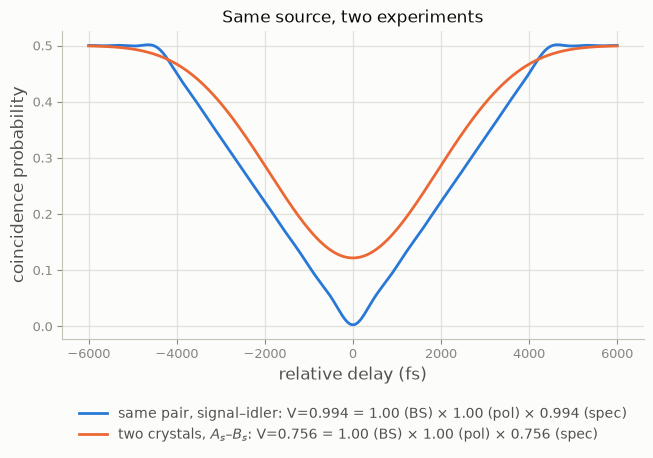

In [9]:
res_A = simulate()
res_B = simulate()   # an independent second crystal with the same design
two_crystal = HOMAnalyzer.independent(res_A, res_B, "signal", "signal", taus_s=taus)
_, purity_A, K_A = SpectralAnalyzer(res_A).schmidt_decomposition()

V_two = two_crystal.visibility
print(f"two-crystal visibility V = {V_two:.4f}")
print(f"Tr[rho_A rho_B]          = {two_crystal.overlap_at_zero_delay:.4f}")
print(f"purity P (Schmidt)       = {purity_A:.4f}   (Schmidt number K = {K_A:.2f})")
print(f"|V - P|                  = {abs(V_two - purity_A):.1e}")

fig, ax = plt.subplots(figsize=(7.5, 4))
SPDC_Plotter.plot_hom_dip(
    {"same pair, signal–idler": same_pair, r"two crystals, $A_s$–$B_s$": two_crystal},
    fig=fig, ax=ax, show_visibility=True,
)
ax.set_title("Same source, two experiments")
plt.show()

The shapes differ too. The two-crystal dip is the Fourier transform of the overlap of the two
**marginal** spectra, so it is smooth and Gaussian-like. Its width is set by the single-photon
bandwidth. The same-pair dip carries the triangular $\pm 4.7$ ps envelope of the type-II phase-matching
function.

### Crystal-to-crystal detuning

Now let crystal B run $\Delta T$ warmer than crystal A. The relevant mismatch is between the two
**signals**, $\Delta\lambda_{AB} = \bar\lambda_{B,s} - \bar\lambda_{A,s}$, not between signal and idler.

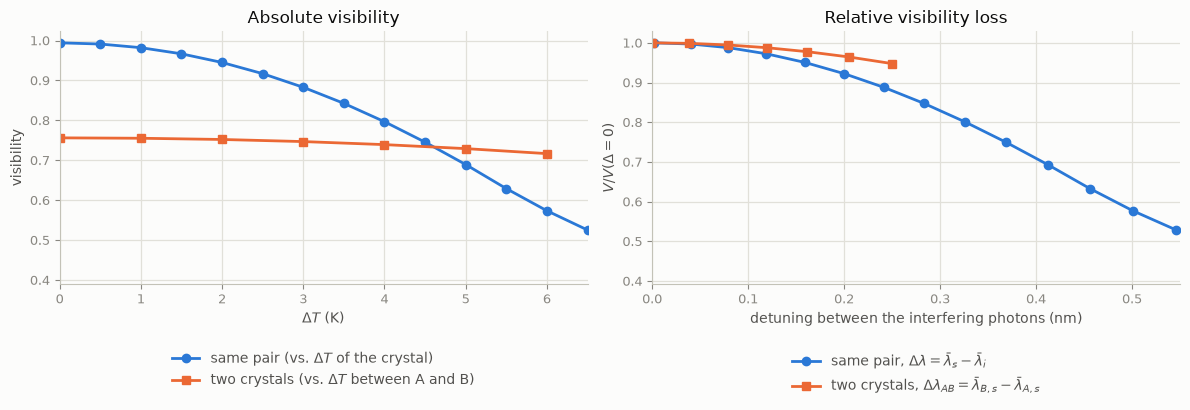

dT_AB = 0 K  ->  dlambda_AB = 0.000 nm,  V = 0.756
dT_AB = 1 K  ->  dlambda_AB = 0.039 nm,  V = 0.755
dT_AB = 2 K  ->  dlambda_AB = 0.079 nm,  V = 0.752
dT_AB = 3 K  ->  dlambda_AB = 0.120 nm,  V = 0.747
dT_AB = 4 K  ->  dlambda_AB = 0.162 nm,  V = 0.739
dT_AB = 5 K  ->  dlambda_AB = 0.205 nm,  V = 0.729
dT_AB = 6 K  ->  dlambda_AB = 0.249 nm,  V = 0.717


In [10]:
signal_A_nm, _ = SpectralAnalyzer(res_A).marginal_centroids_nm()
dT_AB = np.arange(0, 7, 1.0)
V_AB, dlam_AB = [], []
for dT in dT_AB:
    res_Bt = simulate(T_design + dT)
    V_AB.append(HOMAnalyzer.independent(res_A, res_Bt, "signal", "signal", taus_s=taus).visibility)
    signal_B_nm, _ = SpectralAnalyzer(res_Bt).marginal_centroids_nm()
    dlam_AB.append(signal_B_nm - signal_A_nm)
V_AB, dlam_AB = np.array(V_AB), np.array(dlam_AB)

fig, (ax_abs, ax_rel) = plt.subplots(1, 2, figsize=(12, 4.2))
ax_abs.plot(dTs, V_spec, "o-", label="same pair (vs. $\\Delta T$ of the crystal)")
ax_abs.plot(dT_AB, V_AB, "s-", label="two crystals (vs. $\\Delta T$ between A and B)")
ax_abs.set(xlabel=r"$\Delta T$ (K)", ylabel="visibility", xlim=(0, 6.5), title="Absolute visibility")
SPDC_Plotter.style_legend(ax_abs)
ax_rel.plot(detunings, V_spec / V_spec[0], "o-", label=r"same pair, $\Delta\lambda = \bar\lambda_s - \bar\lambda_i$")
ax_rel.plot(dlam_AB, V_AB / V_AB[0], "s-", label=r"two crystals, $\Delta\lambda_{AB} = \bar\lambda_{B,s} - \bar\lambda_{A,s}$")
ax_rel.set(xlabel=r"detuning between the interfering photons (nm)", ylabel=r"$V / V(\Delta=0)$",
           xlim=(0, 0.55), title="Relative visibility loss")
SPDC_Plotter.style_legend(ax_rel)
plt.tight_layout()
plt.show()

for dT, dl, V in zip(dT_AB, dlam_AB, V_AB):
    print(f"dT_AB = {dT:.0f} K  ->  dlambda_AB = {dl:.3f} nm,  V = {V:.3f}")

The two-crystal experiment is much more tolerant to temperature mismatch, for two reasons.
1. A temperature change moves the signal and idler in *opposite* directions. In the same-pair
   experiment their separation grows twice as fast as either photon's own shift.
2. The two-crystal overlap compares two broad marginal spectra. The same-pair overlap compares the
   full JSA with its mirror image, which is more sensitive to small displacements.

The price is the purity ceiling.

### Raising the ceiling: apodized poling

The purity of periodic poling is limited by the side lobes of the sinc-shaped phase-matching function.
Sub-coherence-length domain engineering (`mode="subcoh"`) shapes the phase-matching function into a
Gaussian. This removes the side lobes and makes the JSA nearly separable, so it raises $P$ (and with it
the two-crystal visibility) without spectral filtering.

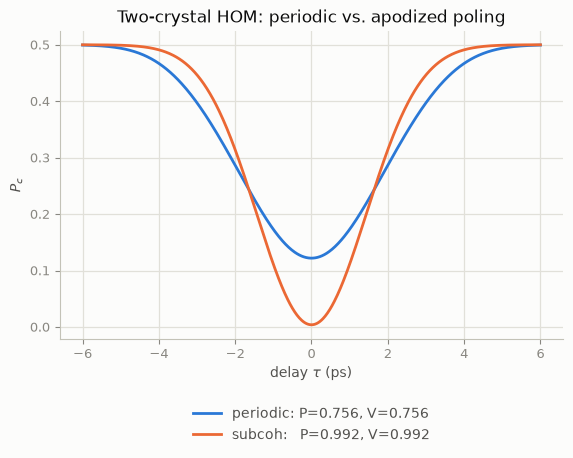

In [11]:
res_A_sc = simulate(mode="subcoh", w=18e-6)
res_B_sc = simulate(mode="subcoh", w=18e-6)
two_crystal_sc = HOMAnalyzer.independent(res_A_sc, res_B_sc, "signal", "signal", taus_s=taus)
_, purity_sc, _ = SpectralAnalyzer(res_A_sc).schmidt_decomposition()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(taus_ps, two_crystal.coincidence_probabilities,
        label=f"periodic: P={purity_A:.3f}, V={V_two:.3f}")
ax.plot(taus_ps, two_crystal_sc.coincidence_probabilities,
        label=f"subcoh:   P={purity_sc:.3f}, V={two_crystal_sc.visibility:.3f}")
ax.set(xlabel=r"delay $\tau$ (ps)", ylabel=r"$P_c$", title="Two-crystal HOM: periodic vs. apodized poling")
SPDC_Plotter.style_legend(ax)
plt.show()

### Experimental notes for two-crystal HOM

- **Fourfold coincidences.** The heralds are part of the measurement. If they are left out, the
  interfering photons aren't conditioned on single pairs, and the analysis above doesn't apply.
- **Multi-pair emission hurts more here.** A double pair from *one* crystal also gives a fourfold
  coincidence, and those events interfere poorly. The visibility therefore falls below $P$, roughly in
  proportion to the mean pair number per pulse. A pump-power series separates this from spectral effects.
- **Timing.** Both crystals must be pumped by the same pulsed laser, with the path lengths matched to well
  within the dip width (≈ ps here). With a CW pump the emission times are random, and independent
  photons interfere only after filtering to a coherence time longer than the detector jitter.
- **Filtering** the heralds or signals also raises $P$, but costs heralding efficiency and count rate.
  Apodized poling raises $P$ without that loss.
- Polarization and beam-splitter balance enter exactly as in Parts 1–2.

## References

1. C. K. Hong, Z. Y. Ou, L. Mandel, "Measurement of subpicosecond time intervals between two photons by
   interference," *Physical Review Letters* **59**, 2044 (1987).
2. W. P. Grice, I. A. Walmsley, "Spectral information and distinguishability in type-II
   down-conversion with a broadband pump," *Physical Review A* **56**, 1627 (1997). This paper covers
   the JSA exchange overlap and why type-II signal–idler HOM visibility is limited.
3. P. J. Mosley *et al.*, "Heralded generation of ultrafast single photons in pure quantum states,"
   *Physical Review Letters* **100**, 133601 (2008). This paper covers HOM between independent sources,
   where the visibility is set by $\mathrm{Tr}[\rho_1\rho_2]$.
4. A. M. Brańczyk, "Hong-Ou-Mandel Interference," arXiv:1711.00080 (2017). A tutorial derivation of
   the coincidence probability, including the delay dependence.
5. A. Fedrizzi, T. Herbst, A. Poppe, T. Jennewein, A. Zeilinger, "A wavelength-tunable fiber-coupled
   source of narrowband entangled photons," *Optics Express* **15**, 15377 (2007). Describes the type-II
   ppKTP Sagnac source.
6. F. Graffitti, P. Barrow, M. Proietti, D. Kundys, A. Fedrizzi, "Independent high-purity photons
   created in domain-engineered crystals," *Optica* **5**, 514 (2018).
   [arXiv:1712.07140](https://arxiv.org/abs/1712.07140). Demonstrates high-purity heralded telecom
   photons from domain-engineered (apodized) KTP without spectral filtering.